# A/B Testing & Statistical Significance Analysis

Analysis of the Marketing A/B Testing dataset. The notebook imports shared functions from `ab_test_analysis.py` so script and notebook calculations stay consistent.

**Interpretation:** causal conclusions depend on assignment and measurement assumptions. The dataset does not document the intended allocation ratio or include a genuine pre-treatment CUPED covariate. Run all cells from the repository root after installing `requirements.txt`.

In [ ]:
from ab_test_analysis import (
    load_data, check_srm, run_ztest, bootstrap_validation,
    business_impact, power_analysis, synthetic_cuped_demo, regression_and_hte,
)

df = load_data()
# Hide the CSV's exported row-index column in the preview; keep the analysis data unchanged.
df.drop(columns=[c for c in df.columns if c.startswith("Unnamed:")], errors="ignore").head()

## 1. Validation and SRM

The loader validates required columns, binary outcomes, group labels, missing values, ad counts, and duplicate user IDs. Because the intended allocation ratio is not documented, SRM is **not tested** by default. Supply a ratio only when supported by the experiment specification.

In [2]:
srm_result = check_srm(df)
# Only if the experiment specification documents the intended split:
# srm_result = check_srm(df, expected_ratio=(0.96, 0.04))

=== Sample Ratio Mismatch (SRM) ===
Observed group counts: {'ad': 564577, 'psa': 23524}
SRM not tested: provide the documented allocation ratio (ad, psa).



## 2. Primary conversion comparison

The two-proportion Z-test reports conversion rates, absolute and relative lift, p-value, and an approximate 95% confidence interval. Statistical significance does not by itself establish business value or causality.

In [3]:
ztest_result = run_ztest(df)

=== Two-proportion Z-test ===
ad conversion: 2.5547%; psa conversion: 1.7854%
Absolute lift: 0.7692%; relative lift: 43.09%
z=7.3701; p=1.70528e-13; approximate 95% CI: [0.5951%, 0.9434%]



## 3. Bootstrap validation

The fixed seed makes the percentile interval reproducible. For binary outcomes, binomial draws are mathematically equivalent to resampling binary observations with replacement.

In [4]:
bootstrap_result = bootstrap_validation(df, n_boot=10_000, seed=42)

=== Bootstrap validation (10,000 resamples; seed=42) ===
Mean lift: 0.7695%; percentile 95% CI: [0.5957%, 0.9389%]
Resamples with positive lift: 100.00%



## 4. Illustrative business impact

This compares observed ad conversions with the number expected at the PSA conversion rate. It is conditional on valid randomization and measurement—not proof that the difference was caused by ads. Cost and guardrail metrics are unavailable.

In [5]:
impact_result = business_impact(df)

=== Illustrative business impact ===
Ad users: 564,577; observed conversions: 14,423
Expected at PSA conversion rate: 10,080.0
Estimated incremental conversions vs PSA baseline: 4,343.0
Interpret only if randomization, measurement, and causal assumptions are credible.



## 5. Retrospective MDE

The MDE describes the approximate effect detectable with the observed sample sizes at the specified alpha and target power. This is retrospective and not independent proof that the experiment was well-powered.

In [6]:
mde_result = power_analysis(df)

=== Retrospective minimum detectable effect (MDE) ===
Sample sizes: ad=564,577; psa=23,524; baseline=1.7854%
Approximate MDE at 80% power and alpha=.05: 0.2552%
Observed lift: 0.7692%. This retrospective calculation is descriptive, not proof of power.



## 6. CUPED — separate synthetic demonstration

The marketing data has no genuine pre-treatment metric. To avoid outcome leakage, this demo creates a separate synthetic randomized experiment: a pre-treatment covariate is generated first, then outcomes are simulated from that covariate and treatment assignment. These results do **not** describe the marketing dataset.

In [7]:
cuped_result = synthetic_cuped_demo(n=20_000, seed=42)

=== Synthetic CUPED demonstration (not the marketing dataset) ===
n=20,000; seed=42; theta=0.0492
Mean within-group variance reduction: 4.5%
Treatment-effect SE reduction: 2.3%
Synthetic result only; real CUPED requires a pre-treatment covariate collected before assignment.



## 7. Exploratory regression and HTE

These models are retained for exploration. `total_ads` is a post-treatment exposure variable, so adjusting for it or interacting it with treatment does not provide a clean causal estimate of effect heterogeneity. A nonsignificant interaction is not evidence that effects are equal across exposure levels.

In [8]:
regression_results = regression_and_hte(df)

=== Exploratory regression / HTE ===
Caution: total_ads is post-treatment exposure; coefficients/interactions are not clean causal estimates.
Additive model coefficients and p-values:
              Coef.         P>|z|
Intercept -4.430664  0.000000e+00
treatment  0.389428  3.970893e-14
total_ads  0.010145  0.000000e+00

Treatment-by-exposure interaction coefficients and p-values:
                        Coef.         P>|z|
Intercept           -4.403465  0.000000e+00
treatment            0.361307  1.604385e-09
total_ads            0.009695  8.353438e-81
treatment:total_ads  0.000467  3.682584e-01
A nonsignificant interaction is not evidence that effects are equal across exposure levels.



## 8. Results at a glance

Run the analysis cells above first. The table below summarizes the observed conversion difference, uncertainty estimates, and the main design caveat directly from the computed results.

In [9]:
import pandas as pd

results_summary = pd.DataFrame([
    {"Metric": "Ad conversion rate", "Result": f"{ztest_result['p_ad']:.3%}"},
    {"Metric": "PSA conversion rate", "Result": f"{ztest_result['p_psa']:.3%}"},
    {"Metric": "Absolute lift (ad − PSA)", "Result": f"{ztest_result['abs_lift']:.3%}"},
    {"Metric": "Relative lift", "Result": f"{ztest_result['rel_lift']:.2f}%"},
    {"Metric": "Two-proportion z-test p-value", "Result": f"{ztest_result['p_value']:.4g}"},
    {"Metric": "Z-test approximate 95% CI", "Result": f"[{ztest_result['ci'][0]:.3%}, {ztest_result['ci'][1]:.3%}]"},
    {"Metric": "Bootstrap percentile 95% CI", "Result": f"[{bootstrap_result['ci'][0]:.3%}, {bootstrap_result['ci'][1]:.3%}]"},
    {"Metric": "SRM status", "Result": srm_result['status']},
])
results_summary

,Metric,Result
0,Ad conversion rate,2.555%
1,PSA conversion rate,1.785%
2,Absolute lift (ad − PSA),0.769%
3,Relative lift,43.09%
4,Two-proportion z-test p-value,1.705e-13
5,Z-test approximate 95% CI,"[0.595%, 0.943%]"
6,Bootstrap percentile 95% CI,"[0.596%, 0.939%]"
7,SRM status,not_tested


## 9. Visualize the primary result

The first chart compares observed conversion rates. The second compares the z-test and bootstrap intervals for absolute lift. These are uncertainty intervals for the observed difference, not guarantees of causal impact.

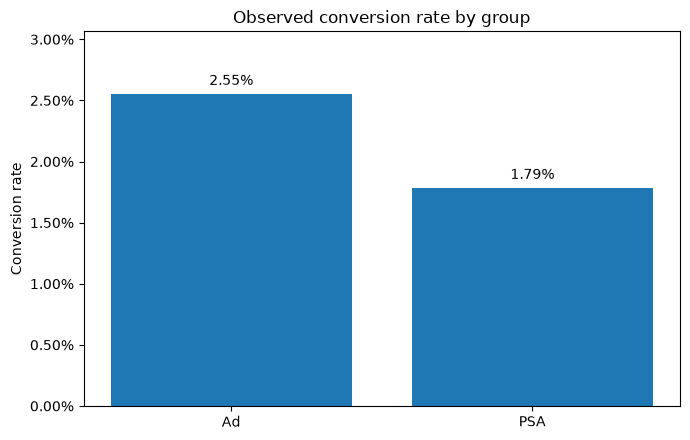

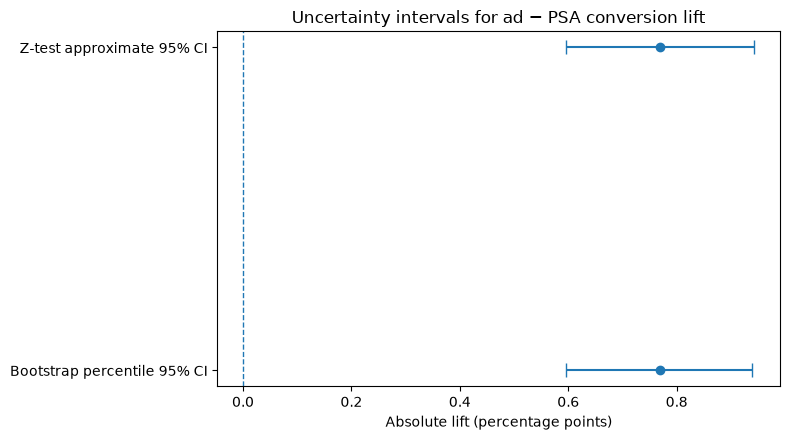

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Observed conversion rates by experiment group
labels = ["Ad", "PSA"]
rates = [ztest_result["p_ad"], ztest_result["p_psa"]]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, rates)
ax.set_title("Observed conversion rate by group")
ax.set_ylabel("Conversion rate")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.bar_label(bars, labels=[f"{rate:.2%}" for rate in rates], padding=4)
ax.set_ylim(0, max(rates) * 1.2)
fig.tight_layout()
plt.show()

# Compare uncertainty intervals for the absolute conversion-rate lift
z_lift = ztest_result["abs_lift"]
b_lift = bootstrap_result["mean_lift"]
centers = [z_lift * 100, b_lift * 100]
lower = [z_lift * 100 - ztest_result["ci"][0] * 100,
         b_lift * 100 - bootstrap_result["ci"][0] * 100]
upper = [ztest_result["ci"][1] * 100 - z_lift * 100,
         bootstrap_result["ci"][1] * 100 - b_lift * 100]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(centers, [1, 0], xerr=[lower, upper], fmt="o", capsize=5)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks([1, 0], ["Z-test approximate 95% CI", "Bootstrap percentile 95% CI"])
ax.set_xlabel("Absolute lift (percentage points)")
ax.set_title("Uncertainty intervals for ad − PSA conversion lift")
fig.tight_layout()
plt.show()

## Conclusion and limitations

The observed ad-group conversion rate is higher than the PSA-group rate in this dataset, and the two-proportion test and bootstrap interval provide consistent evidence of a positive observed difference. Interpret this as causal only if assignment, data quality, and experiment implementation support that conclusion.

The dataset does not document the intended allocation ratio, so SRM remains untested. The estimated incremental conversions are counterfactual estimates, not directly observed causal conversions. CUPED is synthetic, MDE is retrospective, and regression/HTE using `total_ads` remains exploratory because ad exposure is post-treatment. Cost and guardrail metrics are unavailable, so this analysis cannot establish ROI.